# Decaimientos de muón: selección de eventos y vida media

Lee las trazas del DRS4 de `muones/data/` (ver el `README.md` de esa carpeta: cómo bajarlas
y qué corridas hay). Cada evento son 1024 muestras (~1,7 µs) de los tres centelladores.

Un **decaimiento** se ve como dos pulsos en la misma traza:

1. el **pulso de entrada** del muón, que dispara por `u1` y cae siempre cerca de los 207 ns;
2. un **pulso tardío**, el del electrón, un tiempo $\Delta t$ después.

Casi todos los eventos guardados son muones que atraviesan y siguen de largo (un solo
pulso): solo ~0,3 % tiene un pulso tardío claro. El notebook va así:

| paso | qué se hace |
|---|---|
| 1 | indexar todas las trazas una sola vez (los pulsos de cada evento) |
| 2 | armar las variables por evento ($\Delta t$, amplitudes, anchos, topología) |
| 3 | definir los filtros, cada uno por separado |
| 4 | **mirar muchos eventos juntos**: los que pasan y los que rechaza cada filtro |
| 5 | ajustar la vida media y ver si es estable frente a los filtros |
| 6 | guardar la lista de candidatos |

Todo lo pesado está en `decaimientos.py` (al lado de este notebook). Tiene que correrse
desde `muones/analisis`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import decaimientos as dec

# estilo de ESTILO_FIGURAS.md; letra chica para los gráficos de diagnóstico
plt.style.use("seaborn-v0_8")
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 10,
        "mathtext.default": "regular",
        "mathtext.fontset": "cm",
        "legend.frameon": True,
        "figure.dpi": 90,
    }
)
ESTILO_INFORME = {
    k: 14
    for k in (
        "font.size",
        "axes.labelsize",
        "xtick.labelsize",
        "ytick.labelsize",
        "legend.fontsize",
    )
}
pd.set_option("display.width", 200)

CARPETA_SALIDA = Path("../salida_decaimientos")

## 1. Índice de eventos

`indexar()` recorre los 31 GB de texto, busca los pulsos de cada canal y guarda el resultado
en `data/_indice/` (61 MB). La primera vez tarda un par de minutos; después se lee del caché
en un segundo. Las trazas completas solo se vuelven a leer para dibujarlas.

Un *pulso* es un tramo donde la señal suavizada (promedio móvil de 6 muestras, ~10 ns, que
anula el ruido periódico de ~100 MHz) baja más de 20 mV respecto de la línea de base local.
De cada pulso se guarda cuándo empieza, su amplitud, su ancho y su área.

In [2]:
ev = dec.indexar()
tab = dec.tabla_eventos(ev)

g = tab.groupby("run", observed=True)
resumen = g.agg(
    eventos=("num", "size"),
    inicio=("ts", "min"),
    fin=("ts", "max"),
    disparos=("num", "max"),
)
resumen["horas"] = (
    (resumen["fin"] - resumen["inicio"]).dt.total_seconds() / 3600
).round(1)
resumen["% guardado"] = (100 * resumen["eventos"] / resumen["disparos"]).round(1)
resumen["% con u3"] = (100 * g["a_ent_u3"].agg(lambda a: float((a > 0).mean()))).round(
    1
)
resumen["tardíos ‰"] = (1000 * g["hay_tardio"].mean()).round(1)
resumen[["inicio", "fin"]] = resumen[["inicio", "fin"]].apply(
    lambda c: c.dt.strftime("%d/%m %H:%M")
)
print(f"{len(ev):,} eventos en {len(ev.runs)} corridas")
resumen

978,340 eventos en 9 corridas


,eventos,inicio,fin,disparos,horas,% guardado,% con u3,tardíos ‰
run,,,,,,,,
run_20260911_135116,235402,11/09 13:51,17/09 14:11,685485,144.3,34.3,50.299999,4.3
run_20260918_135753,103809,18/09 13:57,21/09 22:25,368619,80.5,28.2,53.200001,5.2
run_20260923_175832,34597,23/09 17:58,24/09 14:03,105183,20.1,32.9,52.299999,4.5
run_20260925_135327,196586,25/09 21:09,01/10 14:07,693344,137.0,28.4,52.900002,4.6
run_20261001_141452,13,01/10 14:14,01/10 14:15,39,0.0,33.3,30.799999,0.0
run_20261002_135657,201978,03/10 06:44,09/10 08:06,738987,145.4,27.3,53.000000,4.4
run_20261016_134329,100152,16/10 13:43,22/10 14:03,347595,144.3,28.8,48.599998,6.7
run_20261023_134416,7,23/10 13:44,23/10 13:45,26,0.0,26.9,0.000000,0.0
run_20261023_134533,105796,23/10 13:45,29/10 14:07,395320,144.4,26.8,51.700001,6.6


## 2. Variables por evento

`tabla_eventos` resume cada evento en una fila:

- `a_ent_u1/u2/u3`, `t0`: amplitud del pulso de entrada en cada centellador y su instante en `u1`.
- `hay_tardio`, `dt`, `a_tardio`, `ancho_tardio`, `canal_tardio`: el **primer** pulso que
  aparece más de 40 ns después de la entrada (en cualquier canal, ≥ 30 mV).
- `patron_ent`, `patron_tar`: en qué centelladores hubo entrada / pulso tardío
  (`"110"` = `u1` y `u2`, no `u3`). `frena_en`: último centellador con pulso de entrada.
- `a_extra`: amplitud del mayor pulso tardío **adicional** (un tercer pulso en otro instante).
- `a_antes`: amplitud del mayor pulso **anterior** al disparo.
- `vmax`, `sigma`: mayor excursión positiva y ruido de la traza (para descartar ráfagas).

Un evento en grande, con los pulsos que encontró el detector (▼). Traza clara = cruda,
traza oscura = suavizada.

20260911 idx3 #1247:  dt = 943 ns, pulso tardío de 138 mV en u3


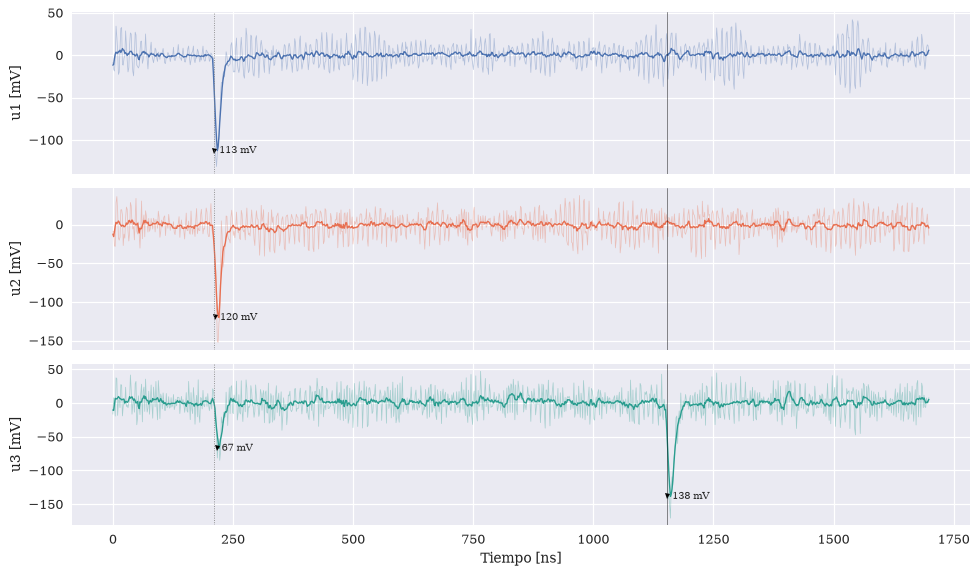

In [3]:
i = np.flatnonzero((tab["a_tardio"] > 100).to_numpy())[0]
print(
    f"{ev.etiqueta(i)}:  dt = {tab['dt'].iloc[i]:.0f} ns, pulso tardío de {tab['a_tardio'].iloc[i]:.0f} mV en u{tab['canal_tardio'].iloc[i]}"
)
fig = dec.ver_evento(ev, i, tab)

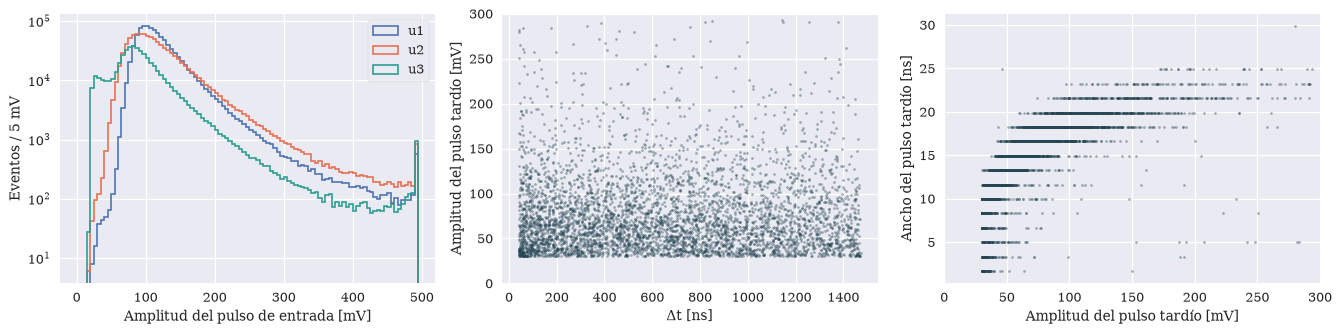

In [4]:
t = tab[tab["hay_tardio"]]
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))

ax = axs[0]
for c, nom in enumerate(dec.CANALES):
    a = tab[f"a_ent_{nom}"]
    ax.hist(
        a[a > 0],
        bins=np.arange(0, 500, 5),
        histtype="step",
        lw=1.3,
        color=dec.COLORES[c],
        label=nom,
    )
ax.set(
    yscale="log", xlabel="Amplitud del pulso de entrada [mV]", ylabel="Eventos / 5 mV"
)
ax.legend()

ax = axs[1]
ax.scatter(t["dt"], t["a_tardio"], s=3, alpha=0.4, color=dec.COLOR_AJUSTE)
ax.set(
    ylim=(0, 300), xlabel=r"$\Delta t$ [ns]", ylabel="Amplitud del pulso tardío [mV]"
)

ax = axs[2]
ax.scatter(t["a_tardio"], t["ancho_tardio"], s=3, alpha=0.4, color=dec.COLOR_AJUSTE)
ax.set(
    xlim=(0, 300),
    xlabel="Amplitud del pulso tardío [mV]",
    ylabel="Ancho del pulso tardío [ns]",
)
fig.tight_layout()

## 3. Filtros

Cada filtro es una máscara independiente; la selección es el **Y** de los que estén en
`ACTIVOS`. Los números de `P` son el punto de partida: se cambian acá y se vuelve a correr
desde esta celda.

| filtro | qué pide | contra qué protege |
|---|---|---|
| `traza limpia` | sin excursiones positivas grandes (`vmax`) ni ruido excesivo (`sigma`) | ráfagas de ruido / interferencia que cruzan el umbral muchas veces |
| `entrada en u1` | pulso de entrada ≥ `a_ent_min` en la ventana de disparo | eventos donde no se sabe cuándo entró el muón |
| `hay pulso tardio` | algún pulso después de la entrada | muones que siguen de largo |
| `amplitud tardio` | pulso tardío ≥ `a_tardio_min` | fluctuaciones del ruido y pospulsos chicos del fotomultiplicador |
| `dt en rango` | `dt_rango[0]` ≤ Δt ≤ `dt_rango[1]` | cola y rebotes del pulso de entrada (Δt chico); pulsos cortados por el final de la traza (Δt grande) |
| `ancho tardio` | ancho dentro de `ancho_rango` | picos de una o dos muestras y ondulaciones lentas de la línea de base |
| `sin pulsos extra` | ningún tercer pulso ≥ `a_extra_min` | trenes de pospulsos y ráfagas |
| `sin pulsos previos` | ningún pulso ≥ `a_extra_min` antes del disparo | eventos donde lo que dispara no es el primer pulso |
| `dos pulsos en un canal` *(opcional)* | el pulso tardío aparece en un centellador que también vio entrar al muón | coincidencias casuales en un centellador que el muón no tocó |
| `tardio donde freno` *(opcional)* | el pulso tardío aparece en el **último** centellador que vio entrar al muón | lo mismo, más estricto |

Los dos opcionales sacan fondo casual pero también decaimientos reales cuyo electrón solo
se ve en el centellador vecino. Equivalencias con la versión anterior de este notebook:
`T_MUERTO` → `dt_rango[0]`; `UMBRAL_MIN` → `a_tardio_min` (ahora es un umbral fijo en mV, no
una fracción del pulso de `u1`); «dos pulsos en un mismo canal» → filtro `dos pulsos en un canal`.

In [5]:
P = dict(
    vmax_max=45,  # mV
    sigma_max=32,  # mV
    a_ent_min=60,  # mV
    a_tardio_min=60,  # mV
    dt_rango=(100, 1400),  # ns
    ancho_rango=(10, 30),  # ns
    a_extra_min=40,  # mV
)
filtros = dec.armar_filtros(tab, **P)

ACTIVOS = [
    "traza limpia",
    "entrada en u1",
    "hay pulso tardio",
    "amplitud tardio",
    "dt en rango",
    "ancho tardio",
    "sin pulsos extra",
    "sin pulsos previos",
]
# opcionales:  ACTIVOS.append("dos pulsos en un canal")   o   ACTIVOS.append("tardio donde freno")

dec.flujo_de_cortes({n: filtros[n] for n in ACTIVOS})

,pasa solo,acumulado,% del anterior
corte,,,
traza limpia,977131,977131,99.9
entrada en u1,977604,976608,99.9
hay pulso tardio,4878,4664,0.5
amplitud tardio,2716,2690,57.7
dt en rango,4292,2421,90.0
ancho tardio,4007,2421,100.0
sin pulsos extra,978256,2421,100.0
sin pulsos previos,978271,2421,100.0


## 4. Mirar muchos eventos

### Visor interactivo

- Las **casillas** prenden y apagan cada filtro; el contador y la galería se actualizan.
- **Mostrar** → `rechazados por: …` muestra los eventos que pasan todos los demás filtros
  tildados pero ese no. Es la vista importante para afinar un corte: si ahí aparecen
  decaimientos claros, el corte está muy duro; si en lo que pasa hay basura, está muy flojo.
- **Corrida**: todas o una sola.
- **Orden**: al azar (muestra representativa), o por Δt / amplitud creciente para mirar
  justo el borde de un corte.
- **Vista**: traza completa, o zoom al pulso tardío (ahí conviene destildar *suavizado*
  para ver la traza cruda).
- **Vetar**: escribir los números de panel (abajo a la izquierda de cada gráfico) de los
  eventos que a ojo *no* son decaimientos. Se guardan en `salida_decaimientos/vetos_manuales.csv`
  y quedan excluidos de todo lo que sigue.

En cada panel: línea punteada gris = entrada del muón; línea negra = pulso tardío elegido.

In [6]:
VETOS = CARPETA_SALIDA / "vetos_manuales.csv"
dec.explorar(ev, tab, filtros, activos=ACTIVOS, ruta_vetos=VETOS)

### Lo mismo, sin widgets

`dec.galeria(ev, indices, tab)` dibuja cualquier lista de eventos. Abajo: una muestra al azar
de los que pasan, y los que quedan justo por debajo del corte de amplitud.

Pasan todos los filtros: 2421 eventos. 24 al azar:


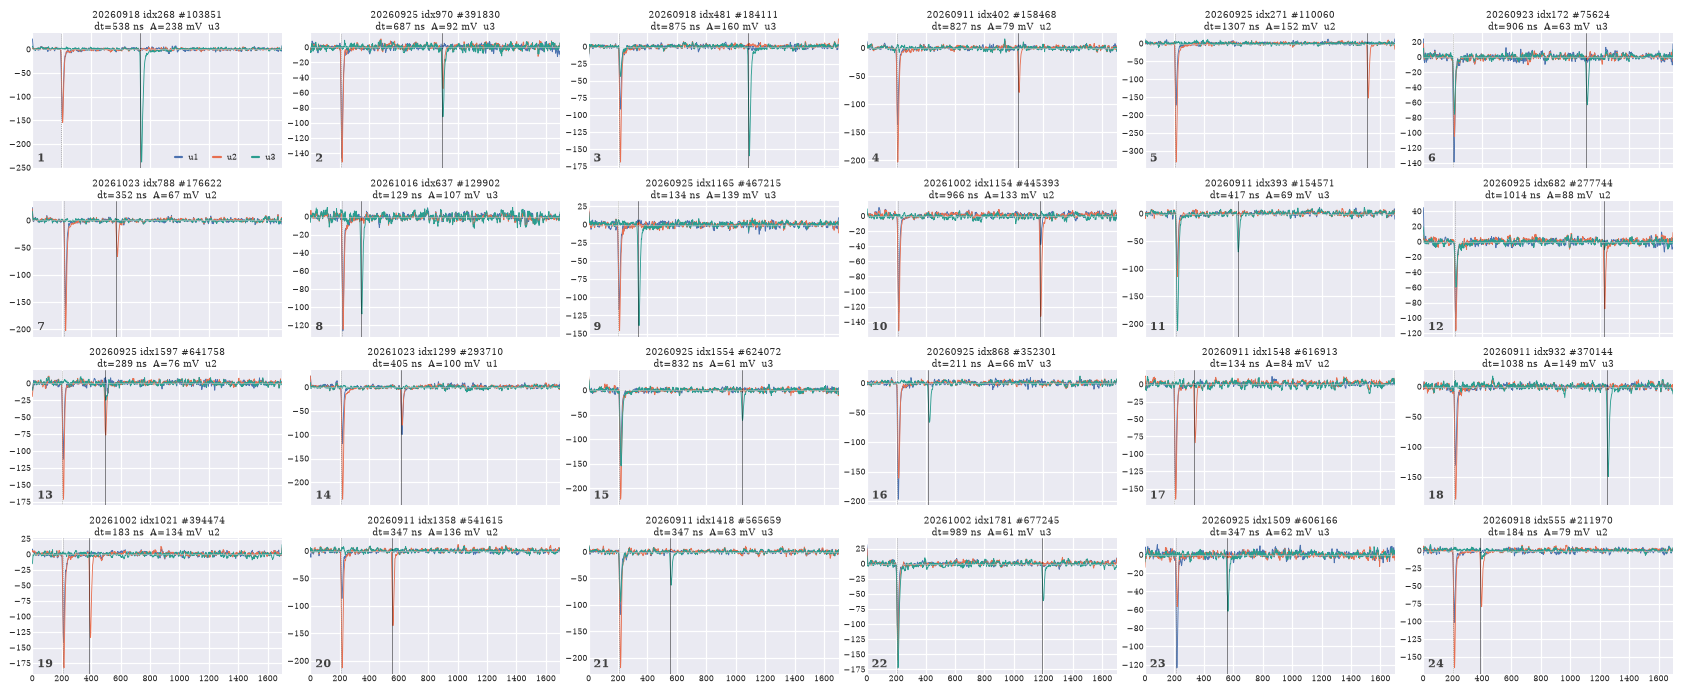

In [7]:
def seleccion():
    "Máscara final: filtros activos y vetos manuales."
    return dec.combinar(filtros, ACTIVOS) & dec.mascara_vetos(
        tab, dec.cargar_vetos(VETOS)
    )


sel = seleccion()
rng = np.random.default_rng(1)
muestra = rng.permutation(np.flatnonzero(sel))[:24]
print(f"Pasan todos los filtros: {sel.sum()} eventos. 24 al azar:")
fig = dec.galeria(ev, muestra, tab)

Rechazados solo por amplitud, los 24 más cercanos al corte (traza cruda, zoom al pulso tardío):


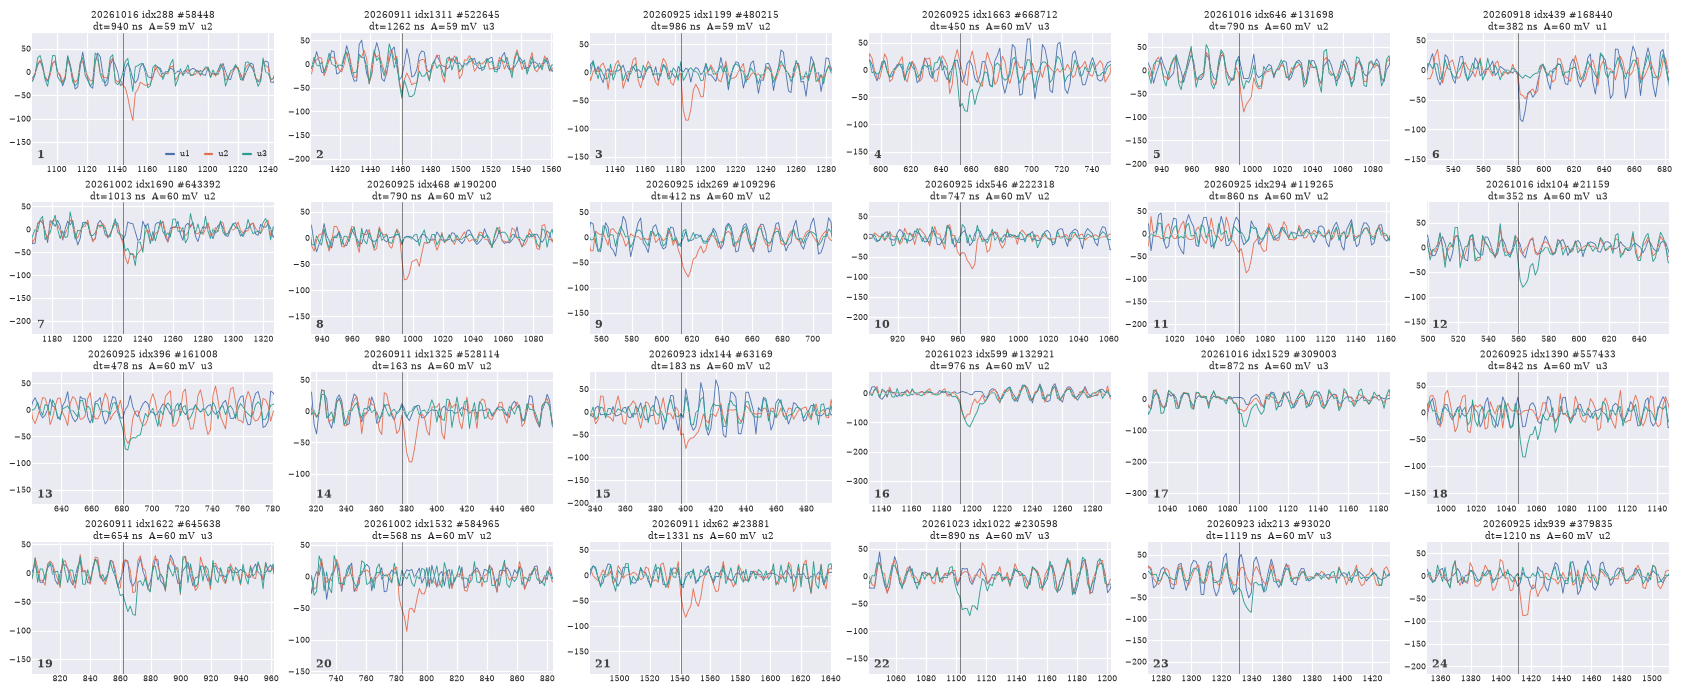

In [8]:
rech = np.flatnonzero(dec.rechazados(filtros, "amplitud tardio", ACTIVOS))
rech = rech[np.argsort(tab["a_tardio"].to_numpy()[rech])][
    -24:
]  # los 24 más cercanos al corte
print(
    "Rechazados solo por amplitud, los 24 más cercanos al corte (traza cruda, zoom al pulso tardío):"
)
fig = dec.galeria(ev, rech, tab, zoom="tardio", suavizar=False)

### Dónde cae cada corte

Distribución de la variable de cada corte (amplitud, Δt, ancho, traza limpia) para los
eventos que pasan **todos los demás** filtros activos. La zona sombreada es lo que ese
corte deja afuera.

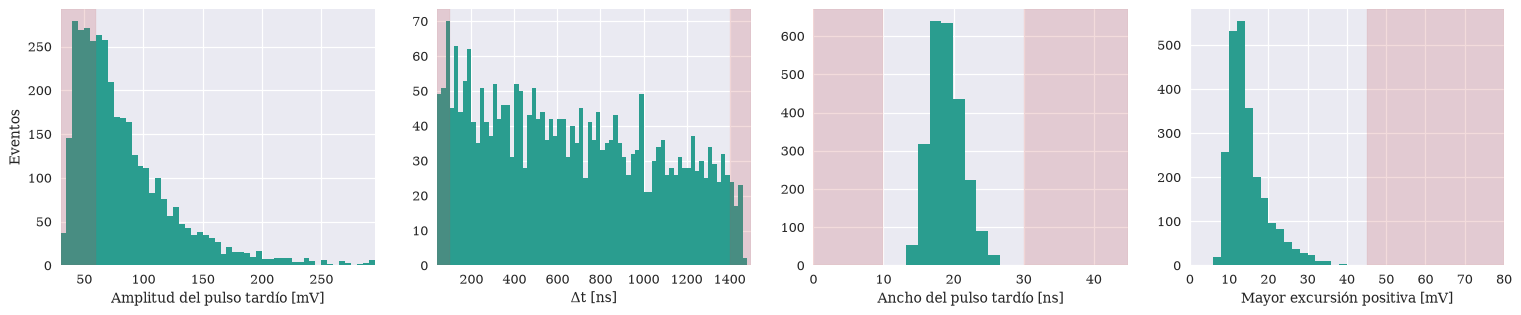

In [9]:
paneles = [
    (
        "amplitud tardio",
        "a_tardio",
        np.arange(30, 300, 5),
        (P["a_tardio_min"], np.inf),
        "Amplitud del pulso tardío [mV]",
    ),
    ("dt en rango", "dt", np.arange(40, 1520, 20), P["dt_rango"], r"$\Delta t$ [ns]"),
    (
        "ancho tardio",
        "ancho_tardio",
        np.arange(0, 45, 1.66),
        P["ancho_rango"],
        "Ancho del pulso tardío [ns]",
    ),
    (
        "traza limpia",
        "vmax",
        np.arange(0, 82, 2),
        (-np.inf, P["vmax_max"]),
        "Mayor excursión positiva [mV]",
    ),
]
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (nombre, var, bins, (lo, hi), etiqueta) in zip(axs, paneles):
    otros = dec.combinar(filtros, [n for n in ACTIVOS if n != nombre])
    ax.hist(tab.loc[otros, var], bins=bins, color=dec.COLOR_DATOS)
    if np.isfinite(lo):
        ax.axvspan(bins[0], lo, color="#C44E52", alpha=0.2)
    if np.isfinite(hi):
        ax.axvspan(hi, bins[-1], color="#C44E52", alpha=0.2)
    ax.set(xlabel=etiqueta, xlim=(bins[0], bins[-1]))
axs[0].set_ylabel("Eventos")
fig.tight_layout()

### Topología

En qué centelladores entró el muón (filas) y en cuáles apareció el pulso tardío (columnas),
para los eventos seleccionados. Los módulos están apilados con una placa de hierro entre
el 2 y el 3, así que una entrada `110` es un muón que frenó en `u2` **o en el hierro**: el
electrón puede salir hacia arriba (tardío en `u2`, `010`) o hacia abajo (tardío en `u3`,
`001`). Una entrada `111` es un muón que frenó en `u3` (tardío `001`). A veces el electrón
alcanza además al centellador vecino.

In [10]:
pd.crosstab(tab.loc[sel, "patron_ent"], tab.loc[sel, "patron_tar"], margins=True)

patron_tar,001,010,011,100,101,110,111,All
patron_ent,,,,,,,,
110,321,973,130,105,0,260,0,1789
111,500,35,46,8,1,21,21,632
All,821,1008,176,113,1,281,21,2421


## 5. Vida media

Ajuste de máxima verosimilitud **sin binear** de

$$ p(\Delta t) = f\,\frac{e^{-\Delta t/\tau}}{\tau\,(e^{-a/\tau}-e^{-b/\tau})} + (1-f)\,\frac{1}{b-a}, \qquad a \le \Delta t \le b $$

con $(a, b)$ = `dt_rango`. El término plano son las coincidencias casuales (un segundo
pulso que no tiene que ver con el muón).

**Ojo con el fondo.** La ventana de la traza (1,3 µs útiles) es más corta que la vida
media, así que una exponencial y una exponencial más un fondo plano se parecen mucho: si
se deja $f$ libre el ajuste no puede separarlos y el error de $\tau$ explota. Por eso se
acota el fondo aparte, con los pulsos **anteriores** al disparo: un pulso casual cae igual
de seguido antes que después de la entrada. Es una cota superior, porque parte de esos
pulsos previos son decaimientos «al revés» (el muón entra sin disparar y el que dispara es
el electrón). El valor de $\tau$ queda entonces entre el ajuste sin fondo y el ajuste con
el fondo fijo en esa cota.

In [11]:
sel = seleccion()
dt = tab.loc[sel, "dt"].to_numpy()

base = dec.combinar(filtros, ["traza limpia", "entrada en u1"])
acc = dec.fondo_accidental(
    ev,
    tab,
    base,
    P["a_tardio_min"],
    P["ancho_rango"],
    P["dt_rango"],
    solo_freno="tardio donde freno" in ACTIVOS,
)
frac_max = min(acc["esperado"] / len(dt), 0.5)
print(f"{len(dt)} eventos seleccionados")
print(
    f"pulsos previos al disparo: {acc['n_previos']}  ->  hasta {acc['esperado']:.0f} ± {acc['error']:.0f} "
    f"casuales en la ventana de Δt ({100 * frac_max:.1f} % de la muestra)"
)

ajustes = {
    "sin fondo": dec.ajustar_vida_media(dt, P["dt_rango"], 0.0),
    "fondo fijo en la cota": dec.ajustar_vida_media(dt, P["dt_rango"], frac_max),
    "fondo libre": dec.ajustar_vida_media(dt, P["dt_rango"], None),
}
pd.DataFrame(
    {
        k: {
            "tau [ns]": r["tau"],
            "- error": r["err_menos"],
            "+ error": r["err_mas"],
            "fondo [%]": 100 * (1 - r["f"]),
        }
        for k, r in ajustes.items()
    }
).T.round(0)

2421 eventos seleccionados
pulsos previos al disparo: 17  ->  hasta 164 ± 40 casuales en la ventana de Δt (6.8 % de la muestra)


,tau [ns],- error,+ error,fondo [%]
sin fondo,2070.0,211.0,264.0,0.0
fondo fijo en la cota,1927.0,197.0,246.0,7.0
fondo libre,1337.0,641.0,972.0,35.0


Figura para el informe (estilo de `ESTILO_FIGURAS.md`; los valores del ajuste van en el
pie de figura, no adentro). Se guarda en `salida_decaimientos/` como `.pdf` y `.png`. Las barras son $\sqrt{N}$ de cada bin; la curva es el ajuste
sin fondo, que se hace sobre los eventos sin binear.

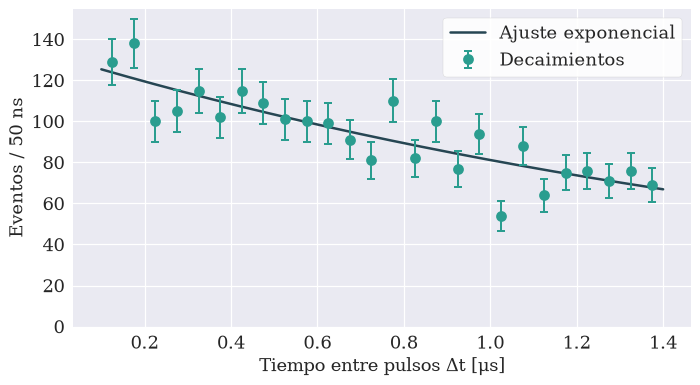

In [12]:
with plt.rc_context(ESTILO_INFORME):
    fig = dec.graficar_ajuste(dt, ajustes["sin fondo"], bins=26)
    fig.savefig(CARPETA_SALIDA / "ajuste_vida_media.pdf", bbox_inches="tight")
    fig.savefig(CARPETA_SALIDA / "ajuste_vida_media.png", bbox_inches="tight", dpi=300)

### ¿Depende de los filtros?

Si la muestra son decaimientos, $\tau$ no debería moverse (más allá del error) al endurecer
los cortes ni al separar por corrida o por centellador. La línea es la vida media del muón
libre (2197 ns).
Todos estos ajustes son **sin fondo**; las barras son el error estadístico de cada ajuste
(las submuestras de un mismo panel comparten eventos, salvo en el de corridas).

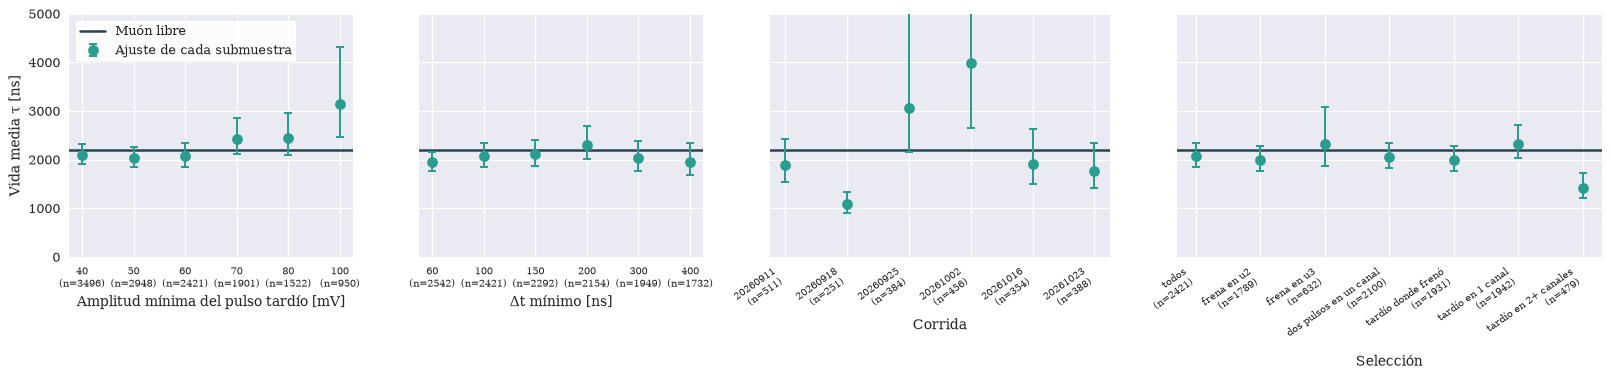

In [13]:
def tau_con(activos=None, mascara=None, **cambios):
    "Ajuste sin fondo cambiando parámetros de los filtros o restringiendo la muestra."
    f = dec.armar_filtros(tab, **{**P, **cambios})
    m = dec.combinar(f, activos or ACTIVOS) & dec.mascara_vetos(
        tab, dec.cargar_vetos(VETOS)
    )
    if mascara is not None:
        m &= mascara
    return dec.ajustar_vida_media(
        tab.loc[m, "dt"], cambios.get("dt_rango", P["dt_rango"]), 0.0
    )


barridos = {
    "Amplitud mínima del pulso tardío [mV]": {
        a: tau_con(a_tardio_min=a) for a in (40, 50, 60, 70, 80, 100)
    },
    r"$\Delta t$ mínimo [ns]": {
        a: tau_con(dt_rango=(a, P["dt_rango"][1]))
        for a in (60, 100, 150, 200, 300, 400)
    },
    "Corrida": {
        r[4:12]: tau_con(mascara=(tab["run"] == r).to_numpy())
        for r in ev.runs
        if (sel & (tab["run"] == r).to_numpy()).sum() > 100
    },
    "Selección": {
        "todos": tau_con(),
        "frena en u2": tau_con(mascara=(tab["frena_en"] == 2).to_numpy()),
        "frena en u3": tau_con(mascara=(tab["frena_en"] == 3).to_numpy()),
        "dos pulsos en un canal": tau_con(activos=ACTIVOS + ["dos pulsos en un canal"]),
        "tardío donde frenó": tau_con(activos=ACTIVOS + ["tardio donde freno"]),
        "tardío en 1 canal": tau_con(mascara=(tab["canales_tardio"] == 1).to_numpy()),
        "tardío en 2+ canales": tau_con(
            mascara=(tab["canales_tardio"] >= 2).to_numpy()
        ),
    },
}

fig, axs = plt.subplots(
    1,
    4,
    figsize=(18, 4.3),
    sharey=True,
    gridspec_kw=dict(width_ratios=[1, 1, 1.2, 1.5]),
)
for ax, (titulo, res) in zip(axs, barridos.items()):
    x = np.arange(len(res))
    tau = np.array([r["tau"] for r in res.values()])
    err = np.array([[r["err_menos"], r["err_mas"]] for r in res.values()]).T
    ax.axhline(2197, color=dec.COLOR_AJUSTE, lw=2, zorder=2, label="Muón libre")
    ax.errorbar(
        x,
        tau,
        yerr=np.where(np.isfinite(err), err, 0),
        fmt="o",
        ms=7,
        capsize=3,
        elinewidth=1.6,
        capthick=1.6,
        mew=1.6,
        color=dec.COLOR_DATOS,
        zorder=3,
        label="Ajuste de cada submuestra",
    )
    largo = titulo in ("Selección", "Corrida")
    ax.set_xticks(
        x,
        [f"{k}\n(n={r['n']})" for k, r in res.items()],
        fontsize=8,
        rotation=35 if largo else 0,
        ha="right" if largo else "center",
    )
    ax.set(xlabel=titulo, ylim=(0, 5000))
axs[0].set_ylabel(r"Vida media $\tau$ [ns]")
axs[0].legend(loc="upper left", facecolor="white", framealpha=0.9)
fig.tight_layout()

### Para leer el resultado

- **Valor de referencia.** El muón libre tiene $\tau = 2197$ ns. En el centellador frenan
  $\mu^+$ y $\mu^-$; los $\mu^-$ además pueden ser capturados por un núcleo de carbono, y su
  vida media efectiva ahí es ~2026 ns. Con la mezcla de rayos cósmicos ($\mu^+/\mu^- \approx 1{,}3$)
  una sola exponencial ajustada da algo cerca de 2,1 µs, no 2,197.
- **Hierro.** Los $\mu^-$ que frenan en la placa de hierro son capturados casi siempre
  (vida media efectiva ~206 ns), así que del hierro salen sobre todo decaimientos de $\mu^+$,
  más una componente corta que solo pesa a $\Delta t$ chico. Si $\tau$ cambiara al subir
  `dt_rango[0]`, esa es la primera sospechosa.
- **Error estadístico.** Con ~2400 decaimientos y una ventana de 1,3 µs el error de $\tau$
  es de ~10 %. Lo que lo limita es la ventana (más corta que $\tau$), no solo la cantidad de
  eventos: una traza más larga achica el error mucho más rápido que más días de medición.
- **Sistemático de fondo.** La diferencia entre «sin fondo» y «fondo fijo en la cota» es
  la incertidumbre por coincidencias casuales. Exigir `tardio donde freno` baja el fondo
  casual a un tercio, a costa de perder ~20 % de los eventos.
- **Antes de confiar en un número**: recorrer en el visor los «rechazados por» de cada
  filtro y las primeras páginas de la selección ordenada por amplitud y por Δt crecientes,
  que es donde se cuela lo que no es decaimiento.

### ¿Se distinguen los $\mu^+$ de los $\mu^-$? Suma de dos exponenciales

Los $\mu^+$ decaen siempre con la vida media libre (2197 ns). Los $\mu^-$ que frenan quedan
ligados a un núcleo y además pueden ser capturados, así que su vida media efectiva depende
del material:

| dónde frena | vida media del $\mu^-$ | fracción que decae (el resto es capturado) |
|---|---|---|
| centellador (carbono) | 2026 ns | 92 % |
| hierro | 206 ns | 9 % |

En el plástico las dos vidas medias difieren 8 %, menos que el error estadístico de este
ajuste (~10 %): ahí no hay forma de separarlas. En el **hierro** sí son muy distintas, y lo
que se puede buscar es una componente rápida de ~206 ns. Como vive a $\Delta t$ chico, para
este ajuste la ventana empieza en 60 ns en lugar de 100.

Se ajusta $f\,e^{-\Delta t/\tau_r} + (1-f)\,e^{-\Delta t/\tau_l}$ por clase de evento. Los
muones que frenan en `u3` solo pueden haber frenado en plástico: sirven de **control**
(no deberían tener componente rápida, y si la tuvieran sería un efecto del detector, por
ejemplo pospulsos).

In [14]:
RANGO_2EXP = (60, 1400)
filtros_2exp = dec.armar_filtros(tab, **{**P, "dt_rango": RANGO_2EXP})
sel_2exp = dec.combinar(filtros_2exp, ACTIVOS) & dec.mascara_vetos(
    tab, dec.cargar_vetos(VETOS)
)
frena, tardio = tab["frena_en"].to_numpy(), tab["patron_tar"].to_numpy()
clases_2exp = {
    "Frenan en u2 o en el hierro": sel_2exp & (frena == 2),
    "Frenan en el hierro (electrón solo en u3)": sel_2exp
    & (frena == 2)
    & (tardio == "001"),
    "Frenan en u3 (plástico, control)": sel_2exp & (frena == 3),
}
modelos = {
    "2197 + 206 ns fijas": dict(tau_lenta=dec.TAU_MU, tau_rapida=dec.TAU_MU_FE),
    "lenta libre + 206 ns": dict(tau_lenta=None, tau_rapida=dec.TAU_MU_FE),
    "2197 ns + rápida libre": dict(tau_lenta=dec.TAU_MU, tau_rapida=None),
}

dos_exp, filas = {}, []
for clase, m in clases_2exp.items():
    x = tab.loc[m, "dt"].to_numpy()
    una = dec.ajustar_vida_media(x, RANGO_2EXP, 0.0)
    for modelo, taus in modelos.items():
        r = dos_exp[clase, modelo] = dec.ajustar_dos_exponenciales(
            x, RANGO_2EXP, **taus
        )
        filas.append(
            {
                "clase": clase,
                "modelo": modelo,
                "eventos": r["n"],
                "τ de una sola exp. [ns]": una["tau"],
                "componente rápida [%]": 100 * r["f"],
                "desde [%]": 100 * r["f_min"],
                "hasta [%]": 100 * r["f_max"],
                "τ lenta [ns]": r["tau_lenta"],
                "τ rápida [ns]": r["tau_rapida"],
                "mejora [σ]": r["sigmas"],
            }
        )
pd.DataFrame(filas).set_index(["clase", "modelo"]).round(1)

eventos  τ de una sola exp. [ns]  componente rápida [%]  desde [%]  hasta [%]  τ lenta [ns]  τ rápida [ns]  mejora [σ]
clase                                     modelo                                                                                                                                        
Frenan en u2 o en el hierro               2197 + 206 ns fijas        1888                   1817.3                    3.6        2.0        5.0        2197.0          206.0         2.0
                                          lenta libre + 206 ns       1888                   1817.3                    4.1        1.0        7.0        2284.7          206.0         1.2
                                          2197 ns + rápida libre     1888                   1817.3                    1.8        1.0        3.0        2197.0           50.7         2.3
Frenan en el hierro (electrón solo en u3) 2197 + 206 ns fijas         341                   1823.1                    6.6        3.0       11.0        2197.0          206.0         1.5
                                          lenta libre + 206 ns        341                   1823.1                   13.7        7.0       19.0        7473.8          206.0         1.8
                                          2197 ns + rápida libre      341                   1823.1                    2.2        1.0        8.0        2197.0           20.0         1.8
Frenan en u3 (plástico, control)          2197 + 206 ns fijas         654                   2453.7                    0.0        0.0        2.0        2197.0          206.0         0.0
                                          lenta libre + 206 ns        654                   2453.7                    2.3        0.0        7.0        2915.8          206.0         0.4
                                          2197 ns + rápida libre      654                   2453.7                    0.0        0.0       57.0        2197.0           80.0         0.0

Con las dos vidas medias fijas en sus valores conocidos (el modelo con menos libertad),
la fracción de eventos en la componente rápida, por clase. Las barras son el intervalo de
68 % del perfil de verosimilitud.

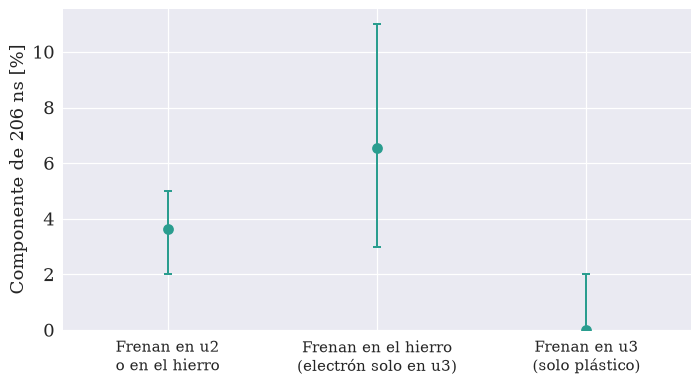

In [15]:
etiquetas = [
    "Frenan en u2\no en el hierro",
    "Frenan en el hierro\n(electrón solo en u3)",
    "Frenan en u3\n(solo plástico)",
]
res = [dos_exp[c, "2197 + 206 ns fijas"] for c in clases_2exp]
f = 100 * np.array([r["f"] for r in res])
err = 100 * np.array([[r["f"] - r["f_min"], r["f_max"] - r["f"]] for r in res]).T

with plt.rc_context(ESTILO_INFORME):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.errorbar(
        np.arange(3),
        f,
        yerr=err,
        fmt="o",
        ms=7,
        capsize=3,
        elinewidth=1.6,
        capthick=1.6,
        mew=1.6,
        color=dec.COLOR_DATOS,
        mfc=dec.COLOR_DATOS,
        mec=dec.COLOR_DATOS,
        zorder=3,
    )
    ax.set_xticks(np.arange(3), etiquetas, fontsize=12)
    ax.set_xlim(-0.5, 2.5)
    ax.set_ylim(0, None)
    ax.set_ylabel("Componente de 206 ns [%]")
    fig.tight_layout()
    fig.savefig(CARPETA_SALIDA / "componente_rapida_por_clase.pdf", bbox_inches="tight")
    fig.savefig(
        CARPETA_SALIDA / "componente_rapida_por_clase.png", bbox_inches="tight", dpi=300
    )

Y la prueba directa de $\mu^+$ contra $\mu^-$ en plástico: suma de 2197 y 2026 ns, las
dos fijas, con la proporción libre. Si los datos pudieran distinguirlas, el intervalo de
la fracción sería angosto.

In [16]:
filas = []
for clase, m in {"Todos": sel, "Frenan en u3 (plástico)": sel & (frena == 3)}.items():
    r = dec.ajustar_dos_exponenciales(
        tab.loc[m, "dt"].to_numpy(),
        P["dt_rango"],
        tau_lenta=dec.TAU_MU,
        tau_rapida=dec.TAU_MU_C,
    )
    f_perfil, dl = r["perfil"]
    filas.append(
        {
            "clase": clase,
            "eventos": r["n"],
            "fracción de 2026 ns [%]": 100 * r["f"],
            "desde [%]": 100 * r["f_min"],
            "hasta [%]": 100 * r["f_max"],
            "Δ(−lnL) entre todo 2197 y todo 2026": abs(dl[0] - dl[-1]),
        }
    )
pd.DataFrame(filas).set_index("clase").round(2)

,eventos,fracción de 2026 ns [%],desde [%],hasta [%],Δ(−lnL) entre todo 2197 y todo 2026
clase,,,,,
Todos,2421,72.8,0.0,100.0,0.11
Frenan en u3 (plástico),632,0.0,0.0,100.0,0.15


**Lectura.**

- **Plástico ($\mu^+$ contra $\mu^-$ en carbono):** no se distinguen. La verosimilitud casi
  no cambia entre «todo 2197 ns» y «todo 2026 ns» (hace falta una diferencia de 0,5 para
  1σ), y el intervalo de la fracción cubre prácticamente de 0 a 100 %. Para separar
  dos vidas medias que difieren 8 % harían falta del orden de 20 veces más eventos solo
  para medir una $\tau$ al 2–3 %, y una ventana de varias vidas medias.
- **Hierro:** con las vidas medias fijas aparece una componente rápida de unos pocos por
  ciento en los muones que pueden haber frenado en el hierro, y ninguna en el control de
  plástico. Va en el sentido esperado, pero la mejora del ajuste es de ~2σ: es un
  indicio, no una detección. Depende de incluir los eventos de 60 a 100 ns (con la ventana
  desde 100 ns desaparece), que es también donde más pesan las colas del pulso de entrada.
  Además, cuando se deja libre la vida media rápida el ajuste prefiere ~50 ns y no 206 ns:
  los datos ven un exceso a $\\Delta t$ muy chico, pero no alcanzan para decir que su
  constante de tiempo sea la de la captura en hierro.
- Si la componente rápida fuera toda de electrones de $\mu^-$ que decaen en el hierro, se
  esperaría como mucho ~10 % (si *todos* los eventos de la clase vinieran del hierro);
  mezclados con los que frenan en `u2`, unos pocos por ciento es lo razonable.

## 6. Guardar los candidatos

Una fila por evento seleccionado, en `salida_decaimientos/candidatos.csv`. Las columnas
`archivo`, `evento` y `dt_ns` son las mismas que usa `histograma_decaimientos.ipynb`, así
que alcanza con apuntar su `RUTA_RESUMEN` a este archivo. (No pisa `resumen.csv`, la lista
de la versión anterior.)

In [17]:
s = tab[sel]
salida = pd.DataFrame(
    {
        "archivo": s["run"].astype(str) + "_idx" + s["idx"].astype(str) + "_selected",
        "evento": s["num"],
        "ts": s["ts"].dt.strftime("%Y-%m-%d %H:%M:%S.%f").str[:-3],
        "canal": "u" + s["canal_tardio"].astype(str),
        "t1_ns": s["t0"].round(1),
        "A1_mV": s["a_ent_u1"].round(1),
        "t2_ns": s["t_tardio"].round(1),
        "A2_mV": s["a_tardio"].round(1),
        "dt_ns": s["dt"].round(1),
        "entrada_u1u2u3": s["patron_ent"],
        "tardio_u1u2u3": s["patron_tar"],
    }
)
CARPETA_SALIDA.mkdir(exist_ok=True)
salida.to_csv(CARPETA_SALIDA / "candidatos.csv", index=False)
print(f"{len(salida)} candidatos guardados en {CARPETA_SALIDA / 'candidatos.csv'}")
salida.head()

2421 candidatos guardados en ..\salida_decaimientos\candidatos.csv


,archivo,evento,ts,canal,t1_ns,A1_mV,t2_ns,A2_mV,dt_ns,entrada_u1u2u3,tardio_u1u2u3
264,run_20260911_135116_idx1_selected,726,2026-09-11 14:01:04.542,u3,194.199997,178.500000,728.799988,64.599998,534.599976,111,001
431,run_20260911_135116_idx3_selected,1247,2026-09-11 14:07:47.869,u3,210.800003,112.500000,1153.800049,138.500000,943.000000,111,001
1352,run_20260911_135116_idx11_selected,4180,2026-09-11 14:46:49.488,u2,202.500000,199.199997,821.799988,133.899994,619.200012,110,010
1867,run_20260911_135116_idx15_selected,5758,2026-09-11 15:07:31.924,u3,202.500000,100.900002,1372.900024,80.900002,1170.400024,111,001
3073,run_20260911_135116_idx25_selected,9553,2026-09-11 15:57:11.607,u1,202.500000,91.599998,313.799988,77.900002,111.199997,110,110


## 7. Qué dice la amplitud de los pulsos

La amplitud del pulso de entrada mide la energía que el muón **deja** en el centellador,
no la energía que trae. Un muón que atraviesa (GeV) es de ionización mínima: deja
~2 MeV por cm de plástico casi sin importar su energía, y la forma de la distribución (pico
con cola larga hacia arriba) viene de las fluctuaciones de esa pérdida (Landau), del camino
recorrido dentro de la barra y de la colección de luz. Por eso de los muones que atraviesan
no se puede sacar su espectro de energía.

Lo que sí se ve es la diferencia con los muones que **frenan**: son lentos (decenas de MeV)
y un muón lento ioniza más (Bethe-Bloch). Abajo se compara, en el último centellador que
tocó el muón, la amplitud de entrada de los candidatos a decaimiento con la de los muones
que siguen de largo. Cada amplitud está dividida por la del pico de los que atraviesan en
ese mismo canal, para poder juntar `u2` y `u3` (los fotomultiplicadores no tienen la misma
ganancia).

In [18]:
limpio = dec.combinar(filtros, ["traza limpia", "entrada en u1"])
pasante = limpio & ~tab["hay_tardio"].to_numpy() & (tab["a_antes"].to_numpy() == 0)
frenado = sel & tab["tardio_en_freno"].to_numpy()


def pico(a):
    "Amplitud más probable (moda del histograma)."
    h, b = np.histogram(a, bins=np.arange(0, 500, 4))
    return 0.5 * (b[h.argmax()] + b[h.argmax() + 1])


filas, rel_pasan, rel_frenan = [], [], []
for patron, canal in (("110", "u2"), ("111", "u3")):
    es = (tab["patron_ent"] == patron).to_numpy()
    a_p = tab.loc[pasante & es, f"a_ent_{canal}"].to_numpy()
    a_f = tab.loc[frenado & es, f"a_ent_{canal}"].to_numpy()
    rel_pasan.append(a_p / pico(a_p))
    rel_frenan.append(a_f / pico(a_p))
    filas.append(
        {
            "último centellador": canal,
            "frenados": len(a_f),
            "pico de los que atraviesan [mV]": pico(a_p),
            "mediana, atraviesan [mV]": np.median(a_p),
            "mediana, frenan [mV]": np.median(a_f),
            "cociente de medianas": np.median(a_f) / np.median(a_p),
        }
    )
rel_pasan, rel_frenan = np.concatenate(rel_pasan), np.concatenate(rel_frenan)
pd.DataFrame(filas).set_index("último centellador").astype(float).round(2)

,frenados,pico de los que atraviesan [mV],"mediana, atraviesan [mV]","mediana, frenan [mV]",cociente de medianas
último centellador,,,,,
u2,1363.0,90.0,107.80,161.00,1.49
u3,568.0,82.0,87.28,148.43,1.70


Figura con el estilo de `ESTILO_FIGURAS.md` (la guía no habla de histogramas: los muones
que atraviesan, que son ~10⁶, van como histograma lleno, y los que frenan como puntos con
barras $\sqrt{N}$). Las dos distribuciones están normalizadas a área 1.

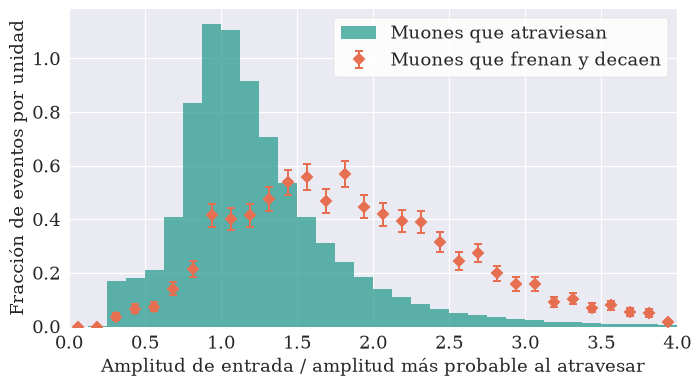

In [19]:
bins = np.arange(0, 4.01, 0.125)
centro, ancho = 0.5 * (bins[1:] + bins[:-1]), bins[1] - bins[0]
n_f = np.histogram(rel_frenan, bins)[0]

with plt.rc_context(ESTILO_INFORME):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(
        rel_pasan,
        bins,
        density=True,
        color=dec.COLOR_DATOS,
        alpha=0.75,
        zorder=2,
        label="Muones que atraviesan",
    )
    ax.errorbar(
        centro,
        n_f / (len(rel_frenan) * ancho),
        yerr=np.sqrt(n_f) / (len(rel_frenan) * ancho),
        fmt="D",
        ms=6,
        capsize=3,
        elinewidth=1.6,
        capthick=1.6,
        mew=1.6,
        color="#E76F51",
        mfc="#E76F51",
        mec="#E76F51",
        zorder=3,
        label="Muones que frenan y decaen",
    )
    ax.set_xlabel("Amplitud de entrada / amplitud más probable al atravesar")
    ax.set_ylabel("Fracción de eventos por unidad")
    ax.set_xlim(0, 4)
    ax.set_ylim(0, None)
    ax.legend(loc="upper right", facecolor="white", framealpha=0.9)
    fig.tight_layout()
    fig.savefig(CARPETA_SALIDA / "amplitud_entrada_frenados.pdf", bbox_inches="tight")
    fig.savefig(
        CARPETA_SALIDA / "amplitud_entrada_frenados.png", bbox_inches="tight", dpi=300
    )

### Solo el canal 1: ¿cuánto de energía hay en la amplitud?

Mirando nada más que la amplitud en `u1` de **todos** los eventos: qué fracción de los
muones termina frenando y decayendo, según cuánto dejaron en `u1`.

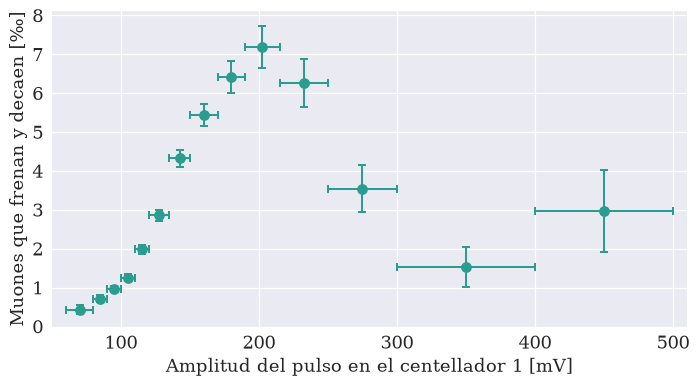

In [20]:
bordes = np.array(
    [60, 80, 90, 100, 110, 120, 135, 150, 170, 190, 215, 250, 300, 400, 500]
)
a1 = tab["a_ent_u1"].to_numpy(float)
n_todos = np.histogram(a1[limpio], bordes)[0]
n_decaen = np.histogram(a1[sel], bordes)[0]
centro_a1 = 0.5 * (bordes[1:] + bordes[:-1])

with plt.rc_context(ESTILO_INFORME):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.errorbar(
        centro_a1,
        1000 * n_decaen / n_todos,
        yerr=1000 * np.sqrt(n_decaen) / n_todos,
        xerr=0.5 * np.diff(bordes),
        fmt="o",
        ms=7,
        capsize=3,
        elinewidth=1.6,
        capthick=1.6,
        mew=1.6,
        color=dec.COLOR_DATOS,
        mfc=dec.COLOR_DATOS,
        mec=dec.COLOR_DATOS,
        zorder=3,
    )
    ax.set_xlabel("Amplitud del pulso en el centellador 1 [mV]")
    ax.set_ylabel("Muones que frenan y decaen [‰]")
    ax.set_xlim(50, 510)
    ax.set_ylim(0, None)
    fig.tight_layout()
    fig.savefig(
        CARPETA_SALIDA / "fraccion_frenan_vs_amplitud_u1.pdf", bbox_inches="tight"
    )
    fig.savefig(
        CARPETA_SALIDA / "fraccion_frenan_vs_amplitud_u1.png",
        bbox_inches="tight",
        dpi=300,
    )

La fracción sube 16 veces entre el pico de los muones rápidos (~100 mV) y el doble de esa
amplitud, y vuelve a caer por encima de ~2,5 veces el pico. Es lo que dice Bethe-Bloch: un
muón deja más energía cuanto más lento va, pero uno que deja más de ~30 MeV en `u1`
(unas 3 veces el pico) ya no tiene energía para llegar a `u2`, que es lo que exige la
selección.

Aun así, en el mejor bin solo ~7 de cada 1000 muones frenan: los otros 993 son muones
rápidos a los que les tocó una fluctuación grande. **La amplitud sola no alcanza para
decir, evento por evento, qué energía tenía el muón.** Lo que sí se puede es usar el
*alcance* (dónde frenó) para separar clases, y la amplitud media en `u1` de cada clase
para leer su energía de la curva de Bethe-Bloch:

In [21]:
def mediana_y_error(x, n=300, rng=np.random.default_rng(0)):
    return np.median(x), np.std([np.median(rng.choice(x, len(x))) for _ in range(n)])


referencia = dec.energia_depositada(2000.0)  # MeV que deja un muón típico (2 GeV)
clases = {
    "Frenan en el centellador 2 o en el hierro": ("110", 2),
    "Frenan en el centellador 3": ("111", 3),
}
filas = []
for nombre, (patron, donde) in clases.items():
    es = (tab["patron_ent"] == patron).to_numpy()
    med_f, err_f = mediana_y_error(a1[sel & es & (tab["frena_en"] == donde).to_numpy()])
    med_p = np.median(a1[pasante & es])
    cociente, err_c = med_f / med_p, err_f / med_p
    T = dec.energia_desde_deposito(cociente * referencia)
    T_lim = dec.energia_desde_deposito(
        np.array([cociente + err_c, cociente - err_c]) * referencia
    )
    filas.append(
        {
            "clase": nombre,
            "eventos": int((sel & es & (tab["frena_en"] == donde).to_numpy()).sum()),
            "mediana u1 [mV]": med_f,
            "mediana u1 de los que atraviesan [mV]": med_p,
            "cociente": cociente,
            "± cociente": err_c,
            "energía dejada en u1 [MeV]": cociente * referencia,
            "energía cinética [MeV]": float(T),
            "T mín": T_lim[0],
            "T máx": T_lim[1],
            "alcance [g/cm²]": float(dec.alcance(T)),
        }
    )
energias = pd.DataFrame(filas).set_index("clase")
energias.round(2)

,eventos,mediana u1 [mV],mediana u1 de los que atraviesan [mV],cociente,± cociente,energía dejada en u1 [MeV],energía cinética [MeV],T mín,T máx,alcance [g/cm²]
clase,,,,,,,,,,
Frenan en el centellador 2 o en el hierro,1789,147.67,115.95,1.27,0.01,12.84,60.55,59.64,61.48,14.88
Frenan en el centellador 3,632,120.86,109.53,1.10,0.01,11.13,84.81,83.02,86.68,24.70


La energía sale de pedir que el depósito medio en 4,5 cm de plástico sea `cociente` veces
el de un muón típico de 2 GeV (10 MeV). El error es solo el estadístico de la mediana;
comparar medianas con pérdidas medias, la respuesta del centellador y la mezcla de cada
clase agregan fácilmente un 20 %. El **alcance** es cuánto plástico atravesaría un muón de
esa energía desde que entra a `u1`: se puede comparar con lo que hay en la pila (las dos
barras son 9,3 g/cm²; el resto, convertido a hierro, es ~1,3 veces más g/cm²).

Curva: energía media que deja un muón en una barra según su energía. Por encima de
~300 MeV es casi plana, y ahí está el 95 % de los muones: por eso de la amplitud no se
puede sacar el espectro de los que atraviesan. Los puntos son las dos clases de muones
que frenan, puestos sobre la curva a la altura de su depósito medido.

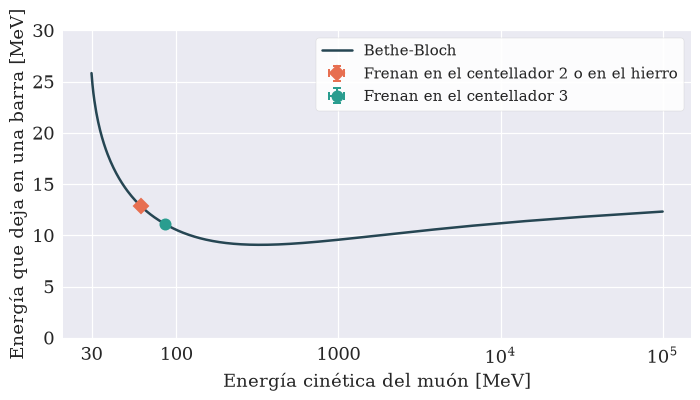

In [22]:
T_curva = np.geomspace(30, 1e5, 600)
marcas = {
    "Frenan en el centellador 2 o en el hierro": ("D", "#E76F51"),
    "Frenan en el centellador 3": ("o", dec.COLOR_DATOS),
}

with plt.rc_context(ESTILO_INFORME):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(
        T_curva,
        dec.energia_depositada(T_curva),
        color=dec.COLOR_AJUSTE,
        lw=2,
        zorder=2,
        label="Bethe-Bloch",
    )
    for nombre, f in energias.iterrows():
        m, c = marcas[nombre]
        ax.errorbar(
            f["energía cinética [MeV]"],
            f["energía dejada en u1 [MeV]"],
            yerr=f["± cociente"] * referencia,
            xerr=[
                [f["energía cinética [MeV]"] - f["T mín"]],
                [f["T máx"] - f["energía cinética [MeV]"]],
            ],
            fmt=m,
            ms=8,
            capsize=3,
            elinewidth=1.6,
            capthick=1.6,
            mew=1.6,
            color=c,
            mfc=c,
            mec=c,
            zorder=3,
            label=nombre,
        )
    ax.set_xscale("log")
    ax.set_xticks(
        [30, 100, 1000, 1e4, 1e5], ["30", "100", "1000", r"$10^4$", r"$10^5$"]
    )
    ax.set_xlabel("Energía cinética del muón [MeV]")
    ax.set_ylabel("Energía que deja en una barra [MeV]")
    ax.set_ylim(0, 30)
    ax.legend(loc="upper right", facecolor="white", framealpha=0.9, fontsize=12)
    fig.tight_layout()
    fig.savefig(CARPETA_SALIDA / "bethe_bloch_barra.pdf", bbox_inches="tight")
    fig.savefig(CARPETA_SALIDA / "bethe_bloch_barra.png", bbox_inches="tight", dpi=300)